# Module 3: Embeddings and a bigram baseline
Companion to `docs/03_embeddings_bigram.html`. We (1) show that an embedding layer is a table lookup, (2) build a character-level
**bigram** language model two ways, by counting and by gradient descent, and check that they agree, (3) compare count-based n-grams with a
**Bengio-style neural language model** (Bengio et al. 2003), and (4) look inside GPT-2's real embedding table.
Runs on a laptop CPU in about 7 minutes (the GPT-2 download is the only network step after the text file).

In [1]:
import os, math, time, urllib.request
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
torch.manual_seed(0); np.random.seed(0)

os.makedirs("data", exist_ok=True)
path = "data/tinyshakespeare.txt"
if not os.path.exists(path):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", path)
text = open(path).read()

## 0. Model code
The count-based n-gram and the neural LM live in one block, pasted from `tools/module03/lm_core.py` so this notebook is standalone. We read it in the sections that use it.

In [2]:
# --- shared by data.py, figs.py and the notebook (mknb.py pastes this file into the notebook) ---
import math, numpy as np, torch, torch.nn as nn, torch.nn.functional as F

def make_vocab(text):
    chars = sorted(set(text))
    stoi = {c: i for i, c in enumerate(chars)}
    return chars, stoi

# ---------- count-based n-gram (the classical baseline) ----------
def ngram_keys(ids, n, V):
    """For every position t >= n: integer code of the n previous symbols (ctx) and of ctx+next (key)."""
    ids = np.asarray(ids, dtype=np.int64)
    ctx = np.zeros(len(ids) - n, dtype=np.int64)
    for k in range(n):                       # base-V number built from ids[t-n .. t-1]
        ctx = ctx * V + ids[k : len(ids) - n + k]
    return ctx, ctx * V + ids[n:]

class CountNgram:
    """P(x | previous n symbols) = (count(ctx, x) + a) / (count(ctx) + a V). Stored sparsely."""
    def __init__(self, ids, n, V):
        self.n, self.V = n, V
        ctx, key = ngram_keys(ids, n, V)
        self.ctx_u, self.ctx_c = np.unique(ctx, return_counts=True)
        self.key_u, self.key_c = np.unique(key, return_counts=True)
    @staticmethod
    def _look(u, c, q):
        i = np.searchsorted(u, q); i[i == len(u)] = 0
        return np.where(u[i] == q, c[i], 0)
    def nll(self, ids, a):
        """mean negative log-likelihood (nats/token) of ids with add-a smoothing"""
        ctx, key = ngram_keys(ids, self.n, self.V)
        cc = self._look(self.ctx_u, self.ctx_c, ctx); ck = self._look(self.key_u, self.key_c, key)
        return float(-np.log((ck + a) / (cc + a * self.V)).mean())

# ---------- Bengio-style neural LM: embed n previous symbols, concat, tanh MLP, softmax ----------
class NeuralLM(nn.Module):
    def __init__(self, V, n, d=16, h=256):
        super().__init__()
        self.n = n
        self.emb = nn.Embedding(V, d)          # the lookup table C of Bengio et al. 2003
        self.hid = nn.Linear(n * d, h)
        self.out = nn.Linear(h, V)
    def forward(self, x):                      # x: (B, n) ints -> logits (B, V)
        e = self.emb(x).flatten(1)             # (B, n*d): concatenated embeddings
        return self.out(torch.tanh(self.hid(e)))

def windows(ids, n):
    ids = torch.as_tensor(ids, dtype=torch.long)
    idx = torch.arange(n)[None, :] + torch.arange(len(ids) - n)[:, None]
    return ids[idx], ids[n:]

@torch.no_grad()
def eval_loss(model, X, Y, bs=20000):
    return float(sum(F.cross_entropy(model(X[i:i+bs]), Y[i:i+bs], reduction="sum") for i in range(0, len(X), bs)) / len(X))

def train_lm(model, X, Y, steps=6000, bs=256, lr=3e-3, seed=0):
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for s in range(steps):
        i = torch.randint(0, len(X), (bs,), generator=g)
        loss = F.cross_entropy(model(X[i]), Y[i])
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return model

@torch.no_grad()
def sample(model, chars, stoi, prompt, n_new, seed=0, temperature=1.0):
    g = torch.Generator().manual_seed(seed)
    ids = [stoi[c] for c in prompt]
    for _ in range(n_new):
        ctx = ids[-model.n:]
        ctx = [0] * (model.n - len(ctx)) + ctx
        p = F.softmax(model(torch.tensor([ctx])) / temperature, -1)[0]
        ids.append(int(torch.multinomial(p, 1, generator=g)))
    return "".join(chars[i] for i in ids)

In [3]:
chars, stoi = make_vocab(text); V = len(chars)
ids = np.array([stoi[c] for c in text])
cut = int(len(ids) * 0.9); tr, te = ids[:cut], ids[cut:]
print(f"{len(text):,} characters, vocabulary V = {V}; train {len(tr):,} / held-out {len(te):,}")
print("uniform guess = ln V =", round(math.log(V), 3), "nats/char  (perplexity", V, ")")

1,115,394 characters, vocabulary V = 65; train 1,003,854 / held-out 111,540
uniform guess = ln V = 4.174 nats/char  (perplexity 65 )


## 1. An embedding layer is a table lookup
`E[x]` (what `nn.Embedding` does) equals `one_hot(x) @ E`. We check that, and that the gradient reaches only the rows that were used.

In [4]:
d = 8
emb = nn.Embedding(V, d)
x = torch.tensor([3, 17, 17, 40])
lookup = emb(x)
onehot = F.one_hot(x, V).float() @ emb.weight          # same thing as a matrix product
print("lookup == one_hot @ E :", torch.allclose(lookup, onehot))

lookup.sum().backward()
rows_with_grad = (emb.weight.grad.abs().sum(1) > 0).nonzero().flatten().tolist()
print("rows that received a gradient:", rows_with_grad, "  (batch used ids", sorted(set(x.tolist())), ")")

lookup == one_hot @ E : True
rows that received a gradient: [3, 17, 40]   (batch used ids [3, 17, 40] )


Only rows 3, 17 and 40 are touched (17 appears twice, so its gradient is accumulated). The other 62 rows are unchanged by this step. This is why rare tokens end up with poorly trained embeddings.

## 2. Cross-entropy by hand
`F.cross_entropy(logits, y)` is the mean of `-log softmax(logits)[y]`. Write it out and compare.

In [5]:
logits = torch.randn(5, V); y = torch.randint(0, V, (5,))
logp = logits - logits.logsumexp(1, keepdim=True)       # log softmax, written out
manual = -logp[torch.arange(5), y].mean()
print(float(manual), float(F.cross_entropy(logits, y)))
assert torch.allclose(manual, F.cross_entropy(logits, y))
print("all-zero logits give a uniform guess:", float(F.cross_entropy(torch.zeros(5, V), y)), "= ln V =", math.log(V))

5.539894104003906 5.539894104003906
all-zero logits give a uniform guess: 4.174387454986572 = ln V = 4.174387269895637


## 3. The bigram model: count it, or train it
A bigram model predicts the next character from the previous one: a `V x V` table of logits `B`, `P(next | prev=i) = softmax(B[i])`.

**By counting.** The maximum-likelihood table is the normalised pair counts.

In [6]:
X, Y = torch.tensor(tr[:-1]), torch.tensor(tr[1:])
Xt, Yt = torch.tensor(te[:-1]), torch.tensor(te[1:])
cnt = torch.zeros(V, V); cnt.index_put_((X, Y), torch.ones(len(X)), accumulate=True)
P_mle = cnt / cnt.sum(1, keepdim=True)
print("train loss of the count table:", float(-torch.log(P_mle[X, Y]).mean()))
print("pairs never seen in training:", int((cnt == 0).sum()), "of", V * V)

# held-out loss needs smoothing, otherwise an unseen pair has probability 0 and loss infinity
P_sm = (cnt + 0.5) / (cnt + 0.5).sum(1, keepdim=True)
print("held-out loss (add-0.5 smoothing):", float(-torch.log(P_sm[Xt, Yt]).mean()))
uni = np.bincount(tr, minlength=V) / len(tr)
print("unigram (no context) held-out loss:", float(-np.log(uni[te]).mean()))

train loss of the count table: 2.451913595199585
pairs never seen in training: 2845 of 4225
held-out loss (add-0.5 smoothing): 2.4819822311401367
unigram (no context) held-out loss: 3.3473284841065922


**By gradient descent.** Treat `B` as parameters, start from zeros (uniform), and minimise the cross-entropy. For each row the gradient is the model's predicted distribution minus the empirical one, so it vanishes exactly at the count solution.

after 500 steps: 2.4530  vs count solution 2.4519  (gap 0.00104)
largest difference between softmax(B) and the counted probabilities: 0.004314780235290527


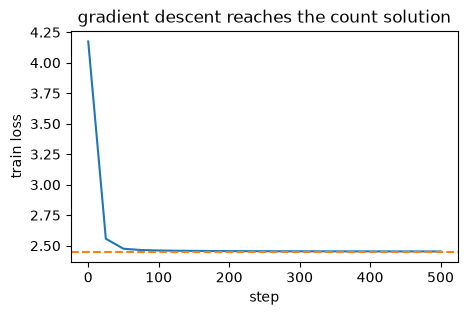

In [7]:
B = torch.zeros(V, V, requires_grad=True)
opt = torch.optim.Adam([B], lr=0.1)
curve = []
for step in range(501):
    loss = F.cross_entropy(B[X], Y)                     # B[X] is an embedding lookup whose output is the logits
    if step % 25 == 0: curve.append((step, loss.item()))
    opt.zero_grad(); loss.backward(); opt.step()
mle = float(-torch.log(P_mle[X, Y]).mean())
print(f"after 500 steps: {curve[-1][1]:.4f}  vs count solution {mle:.4f}  (gap {curve[-1][1]-mle:.5f})")
print("largest difference between softmax(B) and the counted probabilities:", float((F.softmax(B.detach(), 1) - P_mle).abs().max()))
plt.figure(figsize=(5, 3)); plt.plot(*zip(*curve)); plt.axhline(mle, ls="--", c="C1"); plt.xlabel("step"); plt.ylabel("train loss"); plt.title("gradient descent reaches the count solution"); plt.show()

Gradient descent walks to the counting answer (rows of rare characters converge last, which is why the largest probability difference is not exactly zero). **Training a language model by gradient descent is a way of estimating conditional probabilities.** Now look at the table and sample from it.

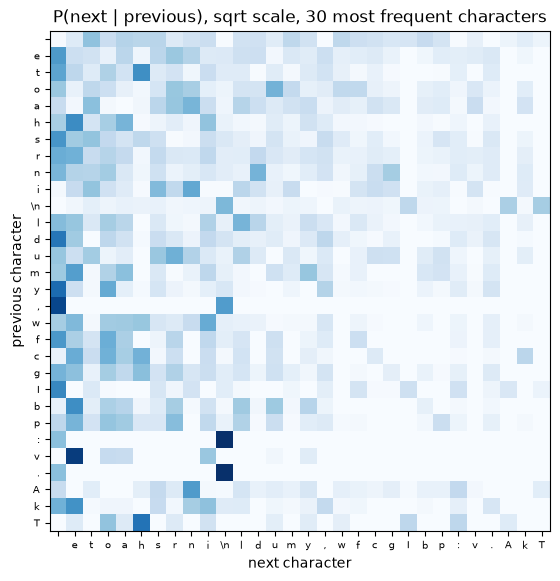

't' -> [('h', 0.341), (' ', 0.246), ('o', 0.088), ('e', 0.065)]
'.' -> [('\n', 0.842), (' ', 0.148), ("'", 0.009), ('-', 0.001)]
'\n' -> [('\n', 0.177), ('T', 0.105), ('A', 0.095), ('W', 0.069)]


In [8]:
top = sorted(range(V), key=lambda i: -uni[i])[:30]
lab = [repr(chars[i])[1:-1] for i in top]
plt.figure(figsize=(7, 6.5)); plt.imshow(P_mle[top][:, top].sqrt().numpy(), cmap="Blues")
plt.xticks(range(30), lab, fontsize=7); plt.yticks(range(30), lab, fontsize=7)
plt.xlabel("next character"); plt.ylabel("previous character"); plt.title("P(next | previous), sqrt scale, 30 most frequent characters"); plt.show()
for c in "t.\n":
    i = stoi[c]; top4 = P_mle[i].topk(4)
    print(repr(c), "->", [(chars[j], round(float(p), 3)) for p, j in zip(top4.values, top4.indices)])

In [9]:
class BigramLM(nn.Module):
    n = 1
    def __init__(s, B): super().__init__(); s.B = B
    def forward(s, x): return s.B[x[:, -1]]
print(sample(BigramLM(B.detach()), chars, stoi, "\n", 240, seed=1))



Caw;

By
M:
The uspl, thartie, by f ces.
Bowin'sanvif tearaicadeemotirail. s, aroflfo aiee, hees n, grit ofustelor d:
By cerisbeatsishisot therdvees, he ir put--de, famy bu iswhit RLLLINCLENa, it rshince norathead, halod, atereisorevig hip


Plausible letter pairs, almost no words: with one character of context the model cannot know which word it is in.

## 4. More context: count n-grams hit a wall, a neural LM does not
**Count-based n-gram** (class `CountNgram` above): condition on the previous `n` characters, `P = (count(ctx, x) + a) / (count(ctx) + a V)`. The table has `V^(n+1)` cells. We pick the smoothing `a` on a validation slice of the training data.

In [10]:
tr_fit, va = tr[: int(len(tr) * 0.9)], tr[int(len(tr) * 0.9):]
ng_rows = []
for n in range(0, 7):
    ng = CountNgram(tr_fit, n, V)
    a = min((ng.nll(va, a), a) for a in (0.003, 0.01, 0.03, 0.1, 0.3, 1.0))[1]
    ng = CountNgram(tr, n, V)
    ng_rows.append((n, ng.nll(tr, a), ng.nll(te, a), len(ng.key_u)))
    print(f"n={n}: a={a:<5} train {ng_rows[-1][1]:.3f}  held-out {ng_rows[-1][2]:.3f}  cells seen {len(ng.key_u):>9,} of {float(V)**(n+1):.2e}")

n=0: a=0.003 train 3.309  held-out 3.347  cells seen        65 of 6.50e+01


n=1: a=0.3   train 2.453  held-out 2.482  cells seen     1,380 of 4.22e+03


n=2: a=0.1   train 1.910  held-out 2.046  cells seen    11,228 of 2.75e+05


n=3: a=0.03  train 1.508  held-out 1.779  cells seen    48,539 of 1.79e+07


n=4: a=0.03  train 1.284  held-out 1.750  cells seen   133,293 of 1.16e+09


n=5: a=0.03  train 1.158  held-out 1.979  cells seen   264,623 of 7.54e+10


n=6: a=0.03  train 1.086  held-out 2.342  cells seen   413,620 of 4.90e+12


The training loss keeps falling (the table memorises), but the held-out loss turns around: most long contexts were never seen.

**Neural LM (Bengio et al. 2003).** Look up the `n` previous characters in a shared embedding table, concatenate, one `tanh` hidden layer, softmax over the vocabulary (class `NeuralLM` above). The number of parameters grows linearly with `n`, not exponentially. Here we train for 4,000 steps at `n` = 1, 2, 4, 8 (the lesson's figure uses 6,000 steps at every `n` from 1 to 8, so the numbers differ slightly).

In [11]:
nl_rows = []
models = {}
for n in (1, 2, 4, 8):
    Xn, Yn = windows(tr, n); Xe, Ye = windows(te, n)
    torch.manual_seed(0); m = NeuralLM(V, n); t0 = time.time(); train_lm(m, Xn, Yn, steps=4000)
    models[n] = m
    nl_rows.append((n, eval_loss(m, Xn, Yn), eval_loss(m, Xe, Ye), sum(p.numel() for p in m.parameters())))
    print(f"n={n}: train {nl_rows[-1][1]:.3f}  held-out {nl_rows[-1][2]:.3f}  params {nl_rows[-1][3]:,}  ({time.time()-t0:.0f}s)")

n=1: train 2.465  held-out 2.492  params 22,097  (9s)


n=2: train 1.987  held-out 2.077  params 26,193  (9s)


n=4: train 1.709  held-out 1.848  params 34,385  (9s)


n=8: train 1.704  held-out 1.858  params 50,769  (11s)


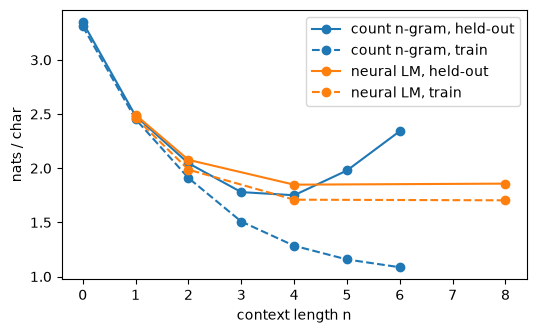

RINNIUS:
Prop me us lead.

ROMEO:
A bling:
It nake virtuear'd man:
Third my spoke all taine, whes not withought of Bustert none your shall tell dotes, her! Well-game fath but swer'd:
Come, let, it rean's likel, wad, in ot, aterent,
For whip


In [12]:
plt.figure(figsize=(6, 3.5))
plt.plot([r[0] for r in ng_rows], [r[2] for r in ng_rows], "o-", c="C0", label="count n-gram, held-out")
plt.plot([r[0] for r in ng_rows], [r[1] for r in ng_rows], "o--", c="C0", label="count n-gram, train")
plt.plot([r[0] for r in nl_rows], [r[2] for r in nl_rows], "o-", c="C1", label="neural LM, held-out")
plt.plot([r[0] for r in nl_rows], [r[1] for r in nl_rows], "o--", c="C1", label="neural LM, train")
plt.xlabel("context length n"); plt.ylabel("nats / char"); plt.legend(); plt.show()
print(sample(models[8], chars, stoi, "\n" * 8, 240, seed=1).lstrip("\n"))

Read the plot honestly: at short contexts (n = 3, 4) the plain count model is as good or better than our small, briefly trained neural model; the neural model's advantage is that it does not collapse as the context grows. Neither can use a long context well, which is what attention (module 4) fixes.

## 5. Inside GPT-2's embedding table
GPT-2 small's `wte` is the same kind of object, `50,257 x 768`, trained inside a deep transformer.

In [13]:
from transformers import GPT2LMHeadModel, GPT2TokenizerFast
tok = GPT2TokenizerFast.from_pretrained("gpt2"); gpt2 = GPT2LMHeadModel.from_pretrained("gpt2").eval()
Wg = gpt2.transformer.wte.weight.detach()
print("wte shape:", tuple(Wg.shape), "=", f"{Wg.numel():,}", "parameters;", f"{Wg.numel() / sum(p.numel() for p in gpt2.parameters()):.1%} of the model")
print("input and output embeddings are the same tensor (weight tying):", gpt2.lm_head.weight.data_ptr() == gpt2.transformer.wte.weight.data_ptr())
ids_ = tok.encode("The cat sat")
print(ids_, [tok.decode([i]) for i in ids_]); print(Wg[ids_][:, :5])

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 6058.41it/s]

wte shape: (50257, 768) = 38,597,376 parameters; 31.0% of the model
input and output embeddings are the same tensor (weight tying): True
[464, 3797, 3332] ['The', ' cat', ' sat']
tensor([[-0.0686, -0.0203,  0.0645, -0.0621, -0.1135],
        [ 0.0100,  0.0366,  0.1640, -0.2185,  0.0285],
        [ 0.0207, -0.1156,  0.0208, -0.2426,  0.1572]])


In [14]:
Wn = Wg / Wg.norm(dim=1, keepdim=True)
def tid(s):
    t = tok.encode(s); assert len(t) == 1, (s, t); return t[0]
def neighbours(s, k=6):
    sims = Wn @ Wn[tid(s)]; top = sims.topk(k + 1).indices[1:]
    return [(tok.decode([int(i)]), round(float(sims[i]), 2)) for i in top]
for s in (" king", " Paris", " Monday", " 1999", " dog", " happy"):
    print(repr(s), neighbours(s))

' king' [(' kings', 0.73), (' King', 0.7), (' queen', 0.66), ('King', 0.6), (' prince', 0.59), (' monarch', 0.58)]
' Paris' [('Paris', 0.83), (' France', 0.63), (' French', 0.58), (' London', 0.58), ('France', 0.57), (' Copenhagen', 0.57)]
' Monday' [(' Tuesday', 0.89), (' Thursday', 0.85), (' Wednesday', 0.84), (' Friday', 0.82), (' Sunday', 0.81), (' Saturday', 0.8)]
' 1999' [(' 1998', 0.89), (' 1997', 0.86), (' 1995', 0.84), (' 2001', 0.83), (' 1996', 0.82), (' 2003', 0.81)]
' dog' [(' dogs', 0.8), (' Dog', 0.73), ('Dog', 0.67), (' canine', 0.65), ('dog', 0.64), (' Dogs', 0.64)]
' happy' [('happy', 0.7), (' Happy', 0.69), (' happier', 0.67), (' unhappy', 0.66), ('Happy', 0.66), (' pleased', 0.63)]


The neighbours are spelling variants (with or without a leading space, capitalised or not) and genuine semantic relatives. Now the analogy test of Mikolov et al. (the query words are excluded from the answers, as is standard).

In [15]:
def analogy(a, b, c, k=5):
    q = Wn[tid(a)] - Wn[tid(b)] + Wn[tid(c)]; q = q / q.norm(); sims = Wn @ q
    for s in (a, b, c): sims[tid(s)] = -9
    return [tok.decode([int(i)]) for i in sims.topk(k).indices]
for a, b, c in [(" king", " man", " woman"), (" Paris", " France", " Italy"), (" walking", " walk", " swim"), (" Rome", " Italy", " Japan")]:
    print(f"{a} - {b} + {c} ->", analogy(a, b, c))

 king -  man +  woman -> [' queen', ' princess', ' Queen', ' kings', 'Queen']
 Paris -  France +  Italy -> ['Paris', ' Milan', ' Italian', 'Italy', ' Rome']
 walking -  walk +  swim -> [' swimming', ' Swim', ' bathing', ' sailing', ' aquatic']


 Rome -  Italy +  Japan -> [' Tokyo', 'Japan', ' Japanese', ' Beijing', 'Tok']


Some work, some do not (for Paris - France + Italy the nearest row is `Paris` itself and `Rome` is only fifth). The structure is real but approximate. One more caution: cosine similarity has a large common offset.

In [16]:
gen = torch.Generator().manual_seed(0); pr = torch.randint(0, Wg.shape[0], (20000, 2), generator=gen)
print("mean cosine between two random rows:", float((Wn[pr[:, 0]] * Wn[pr[:, 1]]).sum(1).mean()))
print("norm of the mean row:", float(Wg.mean(0).norm()), " average row norm:", float(Wg.norm(dim=1).mean()))

mean cosine between two random rows: 0.26845306158065796
norm of the mean row: 2.052130937576294  average row norm: 3.9585366249084473


Finally, a 2-D look at countries and their capitals (PCA fitted on just these 16 tokens). The country-to-capital arrows come out nearly parallel.

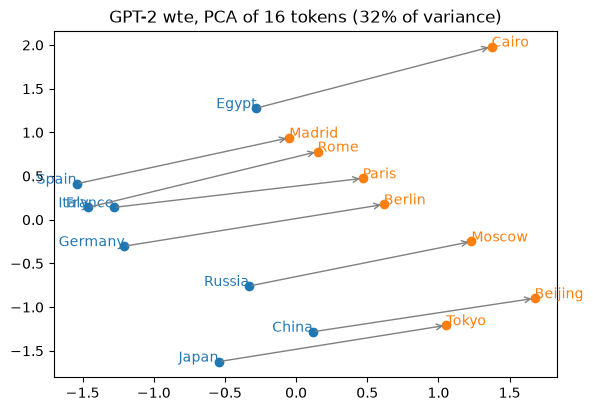

In [17]:
countries = [" France", " Germany", " Italy", " Spain", " Japan", " China", " Russia", " Egypt"]
capitals = [" Paris", " Berlin", " Rome", " Madrid", " Tokyo", " Beijing", " Moscow", " Cairo"]
Mx = Wg[[tid(s) for s in countries + capitals]]; Mc = Mx - Mx.mean(0)
_, S, Vh = torch.linalg.svd(Mc, full_matrices=False); xy = (Mc @ Vh[:2].T).numpy()
plt.figure(figsize=(6.5, 4.5))
for i, (c, k) in enumerate(zip(countries, capitals)):
    plt.annotate("", xy=xy[8 + i], xytext=xy[i], arrowprops=dict(arrowstyle="->", color="gray"))
    plt.text(*xy[i], c.strip(), color="C0", ha="right"); plt.text(*xy[8 + i], k.strip(), color="C1")
plt.scatter(*xy[:8].T, c="C0"); plt.scatter(*xy[8:].T, c="C1")
plt.title(f"GPT-2 wte, PCA of 16 tokens ({(S[:2]**2).sum() / (S**2).sum():.0%} of variance)"); plt.show()

## Exercises
1. **Embedding gradient.** Make a batch whose tokens are all id 5 and check the gradient with `nn.Embedding` is `batch_size` times the gradient for a single occurrence. What does that imply for very frequent tokens?
2. **Smoothing.** The bigram model needs smoothing for held-out data. Try `a` in `(0.01, 0.1, 0.5, 1, 5)` and plot held-out loss against `a`. Why does the best value shrink as the context `n` grows in section 4? (Look at the `a` the validation slice picked.)
3. **Tying.** Change `NeuralLM` so the output layer reuses the embedding matrix (this needs `d = h`, or an extra projection). Does held-out loss at `n = 4` change? How many parameters did you save?
4. **Open-ended: what do the character embeddings learn?** Take `models[8].emb.weight`, project to 2-D with PCA, and label the points. Do vowels group? Capitals vs lowercase? Punctuation? Repeat with embedding sizes `d = 2, 4, 16, 64` and compare held-out loss. Does a 2-D embedding still work?
5. **Open-ended: other languages.** Run the neural LM on another text file (a different language or code). What changes in the learned embeddings?
6. **GPT-2.** Find 5 tokens whose nearest neighbours are *not* semantic (for instance, fragments or odd symbols). What do the neighbours tell you about the data the model saw?